In [36]:
import pandas as pd
import numpy as np

In [37]:
import os
file = [f for f in os.listdir()
if f.endswith(".csv")][0]
print(repr(file))

'e commerce dataset (1).csv'


In [38]:
import pandas as pd
import glob
file = glob.glob("*.csv")[0]
print("File found:",file)
df = pd.read_csv(file, encoding = "latin1")
print("Dataset loaded successfully!")
print(df.shape)

File found: e commerce dataset (1).csv
Dataset loaded successfully!
(9994, 21)


In [39]:
print (df.shape)

(9994, 21)


In [40]:
print(df.columns)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')


In [41]:
print(df.dtypes)

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [42]:
df["Profit_Status"] = "Loss"
df.loc[df["Profit"] > 0, "Profit_Status"] = "Profitable"
print(df["Profit_Status"].value_counts())

Profit_Status
Profitable    8058
Loss          1936
Name: count, dtype: int64


In [43]:
print(df["Profit_Status"].value_counts(normalize=True) * 100)

Profit_Status
Profitable    80.628377
Loss          19.371623
Name: proportion, dtype: float64


In [44]:
features = [
    "Ship Mode" ,
    "Segment" ,
    "Category" ,
    "Sub-Category" , 
    "Region" ,
    "Quantity" ,
    "Discount" , 
    "Sales"
    ]
x = df[features]
y = df["Profit_Status"]
print("Features shape:", x.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(x.columns.tolist())


Features shape: (9994, 8)
Target shape: (9994,)

Feature columns:
['Ship Mode', 'Segment', 'Category', 'Sub-Category', 'Region', 'Quantity', 'Discount', 'Sales']


In [45]:
import sklearn 
print(sklearn.__version__)

1.7.2


In [46]:
import sklearn
print(sklearn.__file__)
from sklearn.model_selection import train_test_split
print("Import successful!")

c:\Users\Preethi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\__init__.py
Import successful!


In [47]:
import sys
print(sys.version)
print(sys.executable)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
c:\Users\Preethi\AppData\Local\Programs\Python\Python311\python.exe


In [48]:
from sklearn.model_selection import train_test_split
print("Import successful!")

Import successful!


In [49]:
from sklearn.model_selection import train_test_split
x_train,x_test ,y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state=42,
    stratify=y
)
print("Training features:", x_train.shape)
print("Testing target:", x_test.shape)
print("Training features:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (7995, 8)
Testing target: (1999, 8)
Training features: (7995,)
Testing target: (1999,)


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,roc_auc_score, roc_curve
print("All required imports successful!")

All required imports successful!


In [51]:
categorical_features = x.select_dtypes(
    include=["object", "category"]
).columns.tolist()
numerical_features = x.select_dtypes(
    include=["number"]
).columns.tolist()
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Ship Mode', 'Segment', 'Category', 'Sub-Category', 'Region']
Numerical features: ['Quantity', 'Discount', 'Sales']


C:\Users\Preethi\AppData\Local\Temp\ipykernel_1236\3516614262.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = x.select_dtypes(


In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
preprocessor = ColumnTransformer(
    transformers=[
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)
print("Preprocessing setup successful!")

Preprocessing setup successful!


In [53]:
model = Pipeline(
    steps = [
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)
print("Model pipeline crfeated successfully!")

Model pipeline crfeated successfully!


In [54]:
model.fit(x_train, y_train)
print("Model training completed successfully!")

Model training completed successfully!


In [55]:
y_pred = model.predict(x_test)
print("First 10 actual values:")
print(y_test.head(10).tolist())
print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
['Profitable', 'Profitable', 'Profitable', 'Profitable', 'Profitable', 'Profitable', 'Profitable', 'Profitable', 'Loss', 'Profitable']

First 10 predicted values:
['Profitable' 'Profitable' 'Profitable' 'Profitable' 'Profitable'
 'Profitable' 'Profitable' 'Profitable' 'Loss' 'Profitable']


In [56]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 94.2 %


In [57]:
cm = confusion_matrix(y_test, y_pred, labels=["Loss","Profitable"])
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 301   86]
 [  30 1582]]


In [58]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        Loss       0.91      0.78      0.84       387
  Profitable       0.95      0.98      0.96      1612

    accuracy                           0.94      1999
   macro avg       0.93      0.88      0.90      1999
weighted avg       0.94      0.94      0.94      1999



In [59]:
y_prob = model.predict_proba(x_test) [:, 1]
print("Model classes:", model.classes_)
print("First 10 probabilities:", y_prob[:10])

Model classes: ['Loss' 'Profitable']
First 10 probabilities: [0.90102012 0.9982642  0.99557151 0.98392077 0.99801413 0.99369107
 0.99512185 0.98789694 0.00258864 0.82623013]


In [60]:
y_test_binary = (y_test == "Profitable").astype(int)
fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob)
auc_value = roc_auc_score(y_test_binary, y_prob)
print("AUC Score:", round(auc_value,4))

AUC Score: 0.9812


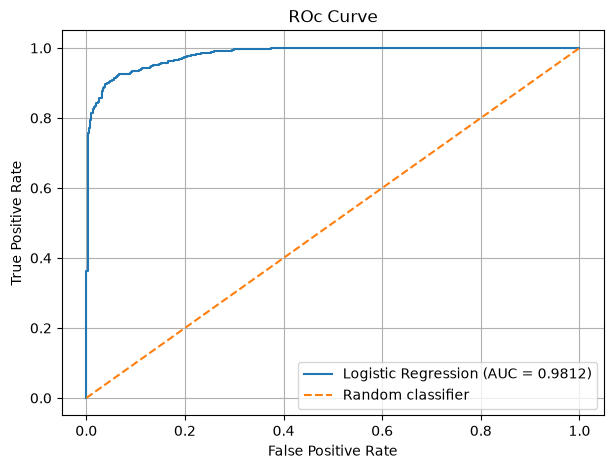

In [61]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 5))
plt.plot(fpr,tpr,label=f"Logistic Regression (AUC = {auc_value:.4f})")
plt.plot([0,1], [0,1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROc Curve")
plt.legend()
plt.grid(True)
plt.show()

# Conclusion

 A Logistic Regression model was developed to classify orders as Profitable or Loss using the e-commerce dataset.
 The model achieved approximately 94.2% accuracy and an AUC score of 0.9812.
 The ROC curve indicates strong classification performance.
 However,the model can still improve its detection of loss- making orders.
 This project demonstrates the use of preprocessing,model training,confusion matrix,classification metrics, and ROC-AUC evaluation in predictive modeling.
